
# **Simulating the solar system using pygame**


Leo Gregg-Allured
leogreggallured@gmail.com

This is a lab book for taking notes and recording the process of creating this simulation of the solar system using the pygame module

## 1. Simulating gravity between two circular objects "red" and "blue"

### 1.1 Full cartesian coordinates

Jul 8 10:22
 - the following code simulates the individual components of gravity in x and y and then uses suvat to find the position of the circles in the following frame.
 - it also outputs the current frame aswell as current x and y positions of the objects along with the forces they are currently experincing in the respective axis
 -the blue circle is fixed and expereinces no forces from the red circle. but the red circle is free to move and does experience the forces from the blue circle

-the force is modelled as newtons law of gravitation except the constants and masses have no units relative to real physics, and are for now just placeholder constants as the code develops into the final simulation


<center>
Newtons law of gravitation:
<center>

$$
F = \frac{G M m}{r^2}
$$

<center>
Suvat (for calculating new position)
<center>

$$
s = ut + \frac{1}{2}at^2
$$


In [ ]:
#This is a simple python project to simulate gravity between two bodys as a simple force
#Leo Gregg-Allured
#leogreggallured@gmail.com
#july 7th 2026

import pygame as pyg
import os

#initliasing the folder to save the simulation frames in for the lab book
output_folder = "simulation frames"
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

#initliase pyg
screen_y = 720
screen_x =1280
pyg.init()
screen = pyg.display.set_mode((screen_x, screen_y))
clock = pyg.time.Clock()
running = True
Framerate = 60
current_frame = 0

#initliase the physcics

time = 1 / Framerate

pi = 3.14159
G = 2000 #this can be any constant and will later be set to the big G constant for gravity we know irl for the solar system simulation

Pos_red_x = screen_x / 2 + 150
Pos_red_y = screen_y / 2 + 400
Pos_blue_x = screen_x / 2 - 150
Pos_blue_y = screen_y / 2 

Red_mass = 5000
Blue_mass = 2000

Initialvelocity_red_x = 0
Initialvelocity_red_y = 0 
Initialvelocity_blue_x = 0
Initialvelocity_blue_y = 0 

#this body of code is the functions used to determine the x and y positions of the next frame

def Get_pos_red_x(): #this is where we will update the position of the red circle dependant on the forces acting on it

    global Pos_red_x
    global time
    global Initialvelocity_red_x

    #can use suvat to determine the next position of the object as a function of the acceloration due to the forces acting on it
    #needs to update every t = 1/framerate seconds

    #Calculate the force acting on red from blue

    difference_x = abs( Pos_blue_x - Pos_red_x)
    print(difference_x)
    if difference_x != 0:
        force_on_red_x = -( G * Blue_mass * Red_mass ) / ( (difference_x)**2 ) #Newtons law of gravitation without direction
    else:
        force_on_red_x = 0
    print(force_on_red_x)

    #Calculate the new position of the object in x after one step in time

    Pos_red_x_OLD = Pos_red_x

    Pos_red_x += Initialvelocity_red_x * time + (1/2) * (force_on_red_x / Red_mass) * ( time**2 )

    #calculate the new initial velocity for the next calculation

    Initialvelocity_red_x = ( Pos_red_x - Pos_red_x_OLD ) / time

    return (Pos_red_x)

def Get_pos_red_y(): #this is where we will update the position of the red circle dependant on the forces acting on it
    
    global Pos_red_y
    global time
    global Initialvelocity_red_y

    difference_y = abs( Pos_blue_y - Pos_red_y)
    print(difference_y)
    if difference_y != 0:
        force_on_red_y = - ( G * Blue_mass * Red_mass ) / ( (difference_y)**2 ) #Newtons law of gravitation without direction
    else:
        force_on_red_y = 0
    print(force_on_red_y)

    #Calculate the new position of the object in x after one step in time

    Pos_red_y_OLD = Pos_red_y

    Pos_red_y += Initialvelocity_red_y * time + (1/2) * (force_on_red_y / Red_mass) * ( time**2 )

    #calculate the new initial velocity for the next calculation

    Initialvelocity_red_y = ( Pos_red_y - Pos_red_y_OLD ) / time

    return (Pos_red_y)



while running:

    # poll for events
    # pyg.QUIT event means the user clicked X to close your window
    for event in pyg.event.get():
        if event.type == pyg.QUIT:
            running = False

    screen.fill("white") # fills the screen with the colour white

    #This body of code is where each frame is drawn out and rendered

    pyg.draw.circle( #Render the first circle "red"
        screen,
        "red",
        (Get_pos_red_x(), Get_pos_red_y()),
        40
    )

    pyg.draw.circle( #Render the second circle "blue"
        screen,
        "blue",
        (Pos_blue_x, Pos_blue_y),
        40
    )

    pyg.display.flip()

    current_frame += 1
    print(current_frame)

    #saves the current frame to the simulation frames folder to be compiled into a video later for the notebook
    frame_filename = os.path.join(output_folder, f"frame_{current_frame:04d}.png")
    pyg.image.save(screen, frame_filename)

    clock.tick(Framerate)

pyg.quit()

<center>
<small> <i> Figure 1, the code for section 1.1 simulating with only catesian coordinates, the below text ( all the random numbers) is the outputed variables from the code, this code is found as (1.1)Gravity.py</i> <small>
<center>

Jul 8 10:26
 -using os module to save each frame pygame is rendering and then using ffmpeg to generate a video from these frames, the terminal command for ffmpeg is seen below, this is ran within the simulation frames directory.

 ffmpeg -framerate 60 -i frame_%04d.png -c:v libx264 -pix_fmt yuv420p output.mp4


In [ ]:
from IPython.display import Video

Video("Videos/output(1.1).mp4", embed = True, width = 600)

<center>
<small> <i> <b> Figure 2</b>, this is a video of the displayed pygame window showing the rendered simulation </i> </small>
<center>

Jul 8 10:40
 - the simulation did not simulate forces as expected, as the components are seperate the distance between the two circles in the independant axis, the simulation thinks the red and blue objects are really close in x despite of the far awawy y resulting in a massive force in the -x direction causing the red circle to fly away rapidly despite of the distance in y.

 this can be seen above in figure 2,

-the flinging away of the red object is due to the distance between them being nearly zero causing a massive force and hence shooting the red circle away rapidly, this wont be an issue for the solar system simulation as the planets do not get close enough for collisions to be accounted for.


### 1.2 Polar coordinates

Oct 2  15:43
 - A much better approximation of gravity that doesnt have the issue with the distances being seperated would be to use two dimensional polar coordinates.
using this coordinate system a measurement for the total distance between the two objects can be calulated and the effects of gravity can be supplied as components of the total force.

- The maths for this can be seen below:


$$
F_{total} = \frac{GMm}{\vec{r}^2} \hat{r}
$$


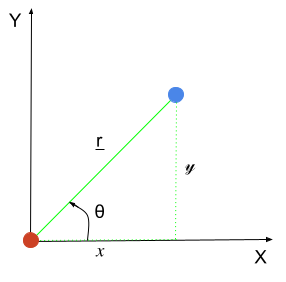

In [ ]:
from IPython.display import Image

Image("Photos/2DPolarCoordinateDiagram.png",embed=True,width=400)

<center>
<small> <i> <b> Figure 3 </b>, diagram of the polar coordinate system where r is the vector with direction pointing towards blue in reds reference frame and the magnitude equal to the distance between the two objects. The angle theta is drawn between r and the x axis, this is very useful for determinig direction  </i> </small>
<center>